## Autoregressive Text Generation using Simple RNN, Bidirectional RNN, LSTM and GRU

**Dataset:** *Alice's Adventures in Wonderland* by Lewis Carroll, downloaded from Project Gutenberg.  
**Dataset source:** https://www.gutenberg.org/files/11/11-0.txt

This notebook preprocesses the text, creates next-word prediction examples, trains four comparable models, evaluates them, generates text at three temperatures, and saves result tables/plots for the GitHub repository.

## 1. Setup and imports

In [ ]:
# If TensorFlow is missing in your environment, uncomment the next line:
# %pip install -q tensorflow pandas matplotlib requests

import re
import time
import json
import random
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Download and describe the dataset
The notebook uses a single English literary text. The source contains narrative prose and dialogue, giving the models sentence patterns, punctuation, and recurring vocabulary to learn.

In [ ]:
DATA_URL = "https://www.gutenberg.org/files/11/11-0.txt"
response = requests.get(DATA_URL, timeout=30)
response.raise_for_status()
raw_text = response.text

print("Downloaded characters:", len(raw_text))
print("\\nPreview:\\n", raw_text[:700])

Downloaded characters: 144696
\nPreview:\n *** START OF THE PROJECT GUTENBERG EBOOK 11 ***

[Illustration]




Alice’s Adventures in Wonderland

by Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0

Contents

 CHAPTER I.     Down the Rabbit-Hole
 CHAPTER II.    The Pool of Tears
 CHAPTER III.   A Caucus-Race and a Long Tale
 CHAPTER IV.    The Rabbit Sends in a Little Bill
 CHAPTER V.     Advice from a Caterpillar
 CHAPTER VI.    Pig and Pepper
 CHAPTER VII.   A Mad Tea-Party
 CHAPTER VIII.  The Queen’s Croquet-Ground
 CHAPTER IX.    The Mock Turtle’s Story
 CHAPTER X.     The Lobster Quadrille
 CHAPTER XI.    Who Stole the Tarts?
 CHAPTER XII.   Alice’s Evidence




CHAPTER I.
Down the Rabbit-Hole


Alice was beginning to get very t


## 3. Preprocess the text
We lowercase the text and tokenize words and common punctuation. To keep training practical in Colab, the experiment uses a reproducible prefix of the book. The vocabulary is limited to the most frequent words; less frequent words are represented by `<unk>`. The same processed data is used for all four models.

In [ ]:
# Remove the Project Gutenberg header/footer when their markers are present.
start_marker = "*** START OF"
end_marker = "*** END OF"
start_pos = raw_text.find(start_marker)
if start_pos != -1:
    newline_pos = raw_text.find("\\n", start_pos)
    if newline_pos != -1:
        raw_text = raw_text[newline_pos + 1:]
end_pos = raw_text.find(end_marker)
if end_pos != -1:
    raw_text = raw_text[:end_pos]

# Use a consistent, manageable portion for all models.
raw_text = raw_text[:180_000].lower()
tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?,;:]", raw_text)

print("Token count:", len(tokens))
print("First 50 tokens:", tokens[:50])

Token count: 31940
First 50 tokens: ['start', 'of', 'the', 'project', 'gutenberg', 'ebook', 'illustration', 'alice', 's', 'adventures', 'in', 'wonderland', 'by', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', '.', 'contents', 'chapter', 'i', '.', 'down', 'the', 'rabbit', 'hole', 'chapter', 'ii', '.', 'the', 'pool', 'of', 'tears', 'chapter', 'iii', '.', 'a', 'caucus', 'race', 'and', 'a', 'long', 'tale', 'chapter', 'iv', '.', 'the', 'rabbit']


In [ ]:
from collections import Counter

MAX_VOCAB = 5000
SEQ_LEN = 12
STRIDE = 2

counts = Counter(tokens)
most_common = [word for word, _ in counts.most_common(MAX_VOCAB - 2)]
vocab = ["<pad>", "<unk>"] + [w for w in most_common if w not in ("<pad>", "<unk>")]
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

encoded = np.array([word_to_id.get(w, word_to_id["<unk>"]) for w in tokens], dtype=np.int32)

# Each input is a fixed-length context; target is the following token.
X_list, y_list = [], []
for i in range(SEQ_LEN, len(encoded), STRIDE):
    X_list.append(encoded[i-SEQ_LEN:i])
    y_list.append(encoded[i])

X = np.asarray(X_list, dtype=np.int32)
y = np.asarray(y_list, dtype=np.int32)

# Keep order intact for a more realistic next-token evaluation.
split = int(len(X) * 0.90)
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

print(f"Vocabulary size: {len(vocab)}")
print(f"Training examples: {len(X_train):,}")
print(f"Validation examples: {len(X_val):,}")
print("Input shape:", X_train.shape, "| Target shape:", y_train.shape)
print("Example input:", " ".join(id_to_word[int(i)] for i in X_train[0]))
print("Expected next word:", id_to_word[int(y_train[0])])

Vocabulary size: 2587
Training examples: 14,367
Validation examples: 1,597
Input shape: (14367, 12) | Target shape: (14367,)
Example input: start of the project gutenberg ebook illustration alice s adventures in wonderland
Expected next word: by


## 4. Define the four models
All models use the same embedding dimension, hidden-unit count, sequence length, optimizer, loss function, batch size, and number of epochs. The Bidirectional RNN reads the observed input window in both directions; it still predicts only the next token after that window.

In [ ]:
EMBED_DIM = 64
UNITS = 64
BATCH_SIZE = 128
EPOCHS = 5

def build_model(model_type, vocab_size):
    inputs = tf.keras.Input(shape=(SEQ_LEN,), dtype="int32")
    x = tf.keras.layers.Embedding(vocab_size, EMBED_DIM, mask_zero=False)(inputs)

    if model_type == "Simple RNN":
        x = tf.keras.layers.SimpleRNN(UNITS)(x)
    elif model_type == "Bidirectional RNN":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.SimpleRNN(UNITS)
        )(x)
    elif model_type == "LSTM":
        x = tf.keras.layers.LSTM(UNITS)(x)
    elif model_type == "GRU":
        x = tf.keras.layers.GRU(UNITS)(x)
    else:
        raise ValueError("Unknown model type: " + model_type)

    outputs = tf.keras.layers.Dense(vocab_size, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name=model_type.lower().replace(" ", "_"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"]
    )
    return model

model_types = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]
print("Models to train:", model_types)

Models to train: ['Simple RNN', 'Bidirectional RNN', 'LSTM', 'GRU']


## 5. Train and evaluate all four models
Validation perplexity is calculated as `exp(validation loss)`. Lower loss/perplexity is better; higher next-word accuracy is better. Training time is measured on the environment used to run this notebook, so it may differ across computers/Colab sessions.

In [ ]:
models = {}
histories = {}
results = []

for model_type in model_types:
    print("\\n" + "=" * 65)
    print("Training:", model_type)
    tf.keras.backend.clear_session()
    model = build_model(model_type, len(vocab))

    start_time = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )
    elapsed = time.time() - start_time

    val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
    val_perplexity = float(np.exp(min(val_loss, 20)))  # avoid numeric overflow in display

    models[model_type] = model
    histories[model_type] = history.history
    results.append({
        "Model": model_type,
        "Validation Loss": float(val_loss),
        "Validation Perplexity": val_perplexity,
        "Next-word Accuracy": float(val_accuracy),
        "Training Time (seconds)": elapsed
    })

results_df = pd.DataFrame(results).sort_values("Validation Loss").reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")

\n=================================================================
Training: Simple RNN
Epoch 1/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 6.3104 - sparse_categorical_accuracy: 0.0718 - val_loss: 5.8453 - val_sparse_categorical_accuracy: 0.0839
Epoch 2/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 5.7254 - sparse_categorical_accuracy: 0.0765 - val_loss: 5.8991 - val_sparse_categorical_accuracy: 0.0839
Epoch 3/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 5.8324 - sparse_categorical_accuracy: 0.0745 - val_loss: 5.9109 - val_sparse_categorical_accuracy: 0.0839
Epoch 4/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 5.6600 - sparse_categorical_accuracy: 0.0764 - val_loss: 5.7865 - val_sparse_categorical_accuracy: 0.0839
Epoch 5/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 5.5664 - sparse_categorical_accuracy: 0.0883 - val_loss: 5.7282 - val_sparse_categorical_accuracy: 0.1027
\n=================================================================
Training: Bid

,Model,Validation Loss,Validation Perplexity,Next-word Accuracy,Training Time (seconds)
0,Bidirectional RNN,5.4702,237.5050,0.1446,12.7393
1,GRU,5.6771,292.0929,0.1271,18.6326
2,LSTM,5.7047,300.2737,0.1033,14.0404
3,Simple RNN,5.7282,307.4271,0.1027,13.4813


Saved model_comparison.csv


## 6. Plot training and validation loss
Use these plots in the GitHub repository and refer to them in your analysis.

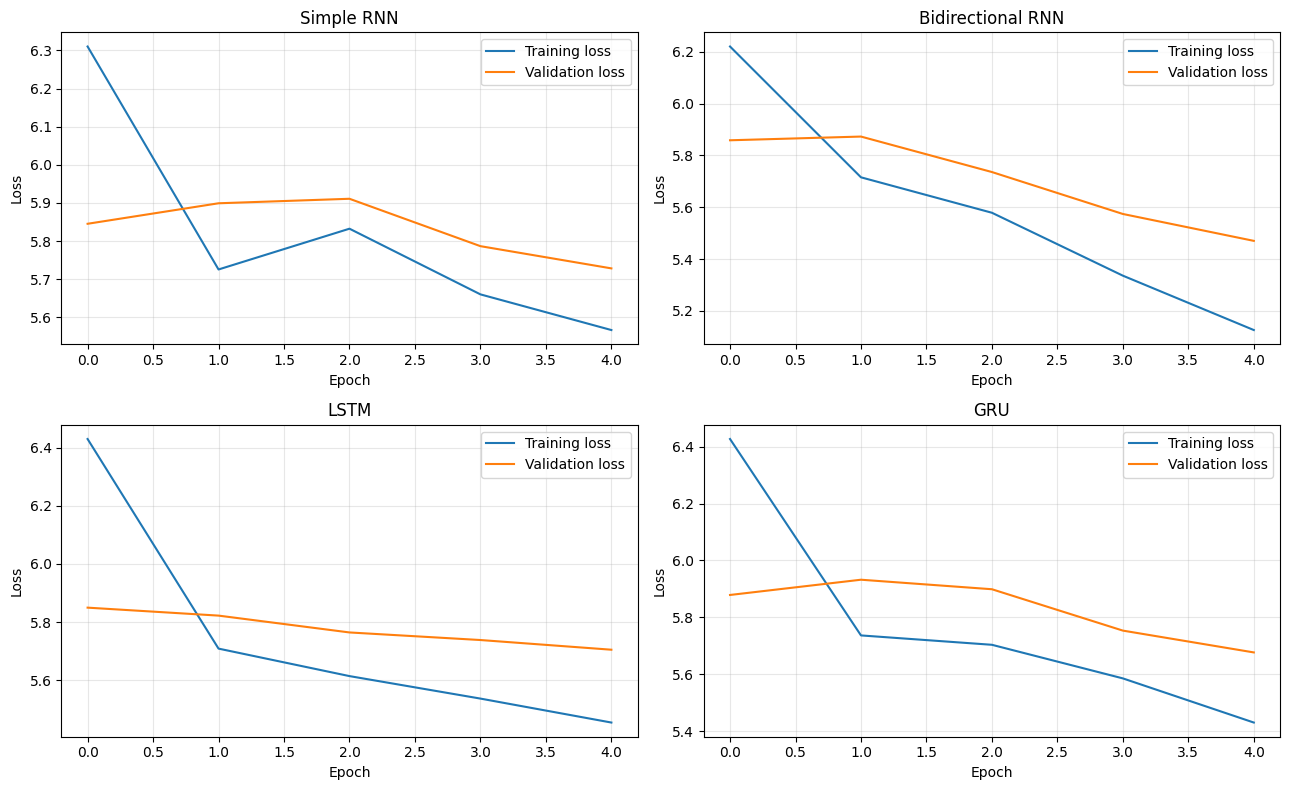

Saved training_validation_loss.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, model_type in zip(axes.flatten(), model_types):
    h = histories[model_type]
    ax.plot(h["loss"], label="Training loss")
    ax.plot(h["val_loss"], label="Validation loss")
    ax.set_title(model_type)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_validation_loss.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved training_validation_loss.png")

## 7. Generate text at different temperatures
The same seed phrase is used for each model. Temperature below 1 generally makes sampling more conservative; temperature above 1 generally increases variety and unpredictability. These are tendencies, not guaranteed outcomes. Review the actual samples and discuss coherence, diversity, contextual consistency, and repetition.

In [ ]:
def sample_next_token(probabilities, temperature=1.0):
    probabilities = np.asarray(probabilities).astype("float64")
    probabilities = np.maximum(probabilities, 1e-12)
    logits = np.log(probabilities) / temperature
    logits = logits - np.max(logits)
    scaled = np.exp(logits)
    scaled = scaled / np.sum(scaled)
    return int(np.random.choice(len(scaled), p=scaled))

def generate_text(model, seed_text, temperature=1.0, words_to_generate=50):
    seed_tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?,;:]", seed_text.lower())
    if not seed_tokens:
        raise ValueError("Please provide a non-empty seed phrase.")

    context = [word_to_id.get(w, word_to_id["<unk>"]) for w in seed_tokens]
    generated = list(seed_tokens)

    for _ in range(words_to_generate):
        window = context[-SEQ_LEN:]
        if len(window) < SEQ_LEN:
            window = [word_to_id["<pad>"]] * (SEQ_LEN - len(window)) + window

        probabilities = model.predict(np.array([window], dtype=np.int32), verbose=0)[0]
        next_id = sample_next_token(probabilities, temperature)
        next_word = id_to_word[next_id]

        generated.append(next_word)
        context.append(next_id)

    # Simple punctuation spacing for readability.
    text = " ".join(generated)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return text

SEED_TEXT = "alice was beginning to"
TEMPERATURES = [0.5, 1.0, 1.5]
WORDS_TO_GENERATE = 50

generated_records = []
for model_type, model in models.items():
    for temperature in TEMPERATURES:
        sample = generate_text(
            model, SEED_TEXT, temperature=temperature,
            words_to_generate=WORDS_TO_GENERATE
        )
        generated_records.append({
            "Model": model_type,
            "Temperature": temperature,
            "Seed": SEED_TEXT,
            "Generated Text": sample
        })
        print(f"\\n--- {model_type} | temperature={temperature} ---\\n{sample}\\n")

generated_df = pd.DataFrame(generated_records)
generated_df.to_csv("generated_text_samples.csv", index=False)
print("Saved generated_text_samples.csv")

\n--- Simple RNN | temperature=0.5 ---\nalice was beginning to the things. and,,, said, it, then.,,, the of, the you, the and, she the she to, and,, all what a and, and the the a, alice, to, and and,\n
\n--- Simple RNN | temperature=1.0 ---\nalice was beginning to given may row ah little ill, to, said it i carefully i there on, life, backs mouth a, hastily who ask hardly to but, myself herself i to: i most before us time, look took not stood so down said, and\n
\n--- Simple RNN | temperature=1.5 ---\nalice was beginning to to often come while ada m wonder nor queen. have be bawled struck twice stamping belongs on hasn yourself needn wooden got i quite everything x zealand, side once on it here frighten come table school re cleared bitter this remember can there the height felt a him\n
\n--- Bidirectional RNN | temperature=0.5 ---\nalice was beginning to dear, and the places, it was, and the get, and the court, and, and she, and the mouse, she i should, and the story. the head. she was,

## 8. Temperature analysis table
Read the samples above and fill in the qualitative judgements based on what the models actually generated. Do not assume the highest temperature or any particular model is automatically best.

In [ ]:
# Optional starter table to fill after inspecting generated_text_samples.csv.
qualitative_template = pd.DataFrame([
    {"Model": m, "Temperature": t, "Coherence (low/medium/high)": "",
     "Diversity (low/medium/high)": "", "Repetition (low/medium/high)": "",
     "Observations from actual sample": ""}
    for m in model_types for t in TEMPERATURES
])
display(qualitative_template)
qualitative_template.to_csv("temperature_analysis_template.csv", index=False)
print("Saved temperature_analysis_template.csv — fill this after reviewing the samples.")

,Model,Temperature,Coherence (low/medium/high),Diversity (low/medium/high),Repetition (low/medium/high),Observations from actual sample
0,Simple RNN,0.5,,,,
1,Simple RNN,1.0,,,,
2,Simple RNN,1.5,,,,
3,Bidirectional RNN,0.5,,,,
4,Bidirectional RNN,1.0,,,,
5,Bidirectional RNN,1.5,,,,
6,LSTM,0.5,,,,
7,LSTM,1.0,,,,
8,LSTM,1.5,,,,
9,GRU,0.5,,,,


Saved temperature_analysis_template.csv — fill this after reviewing the samples.


## 9. Compare models and identify the best model
The lowest validation loss/perplexity is a useful quantitative signal, but the assignment also asks for prediction accuracy, training time, coherence, diversity, contextual consistency, and repetition. Choose the best overall model only after considering both the metrics table and generated samples.

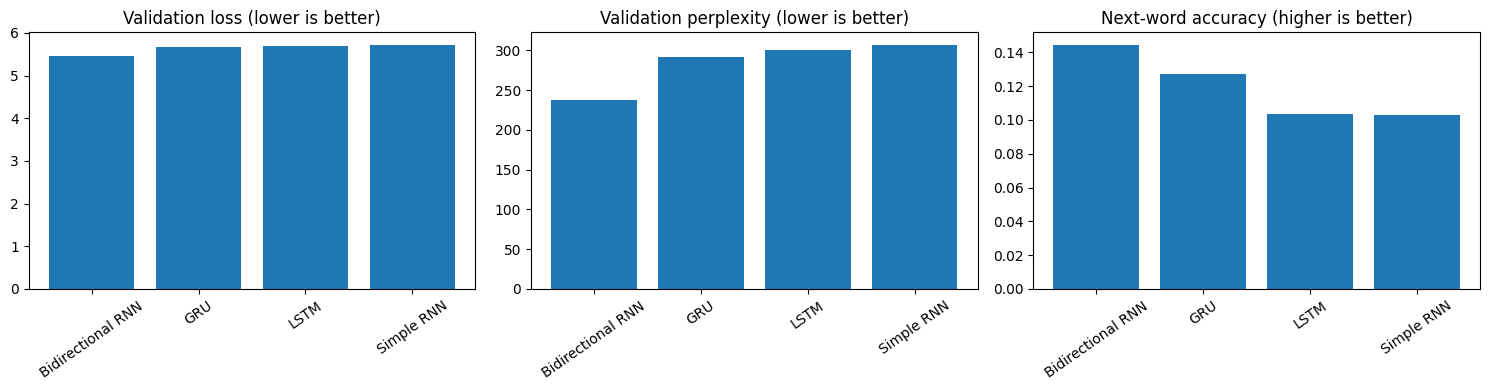

Saved model_metric_comparison.png
\nQuantitative ranking by validation loss:


,Model,Validation Loss,Validation Perplexity,Next-word Accuracy,Training Time (seconds)
0,Bidirectional RNN,5.4702,237.5050,0.1446,12.7393
1,GRU,5.6771,292.0929,0.1271,18.6326
2,LSTM,5.7047,300.2737,0.1033,14.0404
3,Simple RNN,5.7282,307.4271,0.1027,13.4813


In [ ]:
# Quick quantitative visual comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = [
    ("Validation Loss", "Validation loss (lower is better)"),
    ("Validation Perplexity", "Validation perplexity (lower is better)"),
    ("Next-word Accuracy", "Next-word accuracy (higher is better)")
]
for ax, (col, title) in zip(axes, metrics):
    ordered = results_df.sort_values(col, ascending=(col != "Next-word Accuracy"))
    ax.bar(ordered["Model"], ordered[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig("model_metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved model_metric_comparison.png")

print("\\nQuantitative ranking by validation loss:")
display(results_df[["Model", "Validation Loss", "Validation Perplexity",
                    "Next-word Accuracy", "Training Time (seconds)"]].round(4))